The notebook imports SWE-Gym ID parsing from the shared framework module.

In [11]:
import logging
from dataclasses import asdict
import sys
from pathlib import Path

from dotenv import load_dotenv
import pandas as pd
from datasets import load_dataset
from IPython.display import display

logging.basicConfig(level=logging.INFO)

In [12]:
try:
    project_root = next(p for p in Path().cwd().resolve().parents if (p /"env.env").exists())
except StopIteration:
    # Fallback to current working directory if not found
    project_root = Path.cwd()

sys.path.insert(0, str(project_root))

print(f"Project Root: {project_root}")
load_dotenv((project_root /'env.env').resolve())
data_dir = project_root / "datasets"

Project Root: /Users/vedaangchopra/all_data/complete_technical_work/reference_and_learning_content/deep_learning


In [13]:
from model_training.framework.data.post_train.agentic.swe_gym_openhands import structure_trace_ids

### Step-1:- Inspect the dataset

Each row is one attempt at a software issue. This loads the complete `train.raw` split.

In [14]:
from datasets import load_dataset

dataset = load_dataset(
    "SWE-Gym/OpenHands-Sampled-Trajectories",
    split="train.raw",
)

df = dataset.to_pandas().merge(
    load_dataset("SWE-Gym/SWE-Gym", split="train").to_pandas(),
    on="instance_id",
    how="left",
)

print(f"Trajectories: {len(dataset):,} | Combined rows: {len(df):,}")
print(df.columns.tolist())

Trajectories: 6,055 | Combined rows: 6,055
['instance_id', 'run_id', 'resolved', 'messages', 'tools', 'test_result', 'hints_text', 'patch', 'test_patch', 'created_at', 'problem_statement', 'repo', 'base_commit', 'version', 'PASS_TO_PASS', 'FAIL_TO_PASS']


## Step-2:- Structure run and issue IDs

`run_config` keeps labels such as `N`, `no-hint`, and `t02` as text. Their meaning is not assumed. Missing parsed fields indicate an unrecognized ID format.

In [21]:
print("[STAGE] Parse run and instance IDs")
trace_df, run_df, instance_df = structure_trace_ids(df[["instance_id", "run_id", "resolved"]])
print(f"✓ Attempts: {len(trace_df):,} | unique issues: {len(instance_df):,} | unique runs: {len(run_df):,}")
print(f"Unparsed runs: {run_df['max_iterations'].isna().sum()} | unparsed issues: {instance_df['issue_number'].isna().sum()}")
display(trace_df.head(10))

INFO:model_training.framework.data.post_train.agentic.swe_gym_openhands:Structured 6055 traces into 9 runs and 2438 issues


[STAGE] Parse run and instance IDs
✓ Attempts: 6,055 | unique issues: 2,438 | unique runs: 9
Unparsed runs: 0 | unparsed issues: 0


,instance_id,run_id,resolved,model_name,model_date,max_iterations,run_config,run_number,owner,repository,issue_number
0,getmoto__moto-5321,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-tr...,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,5321
1,getmoto__moto-5699,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-tr...,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,5699
2,getmoto__moto-7495,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-tr...,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,7495
3,getmoto__moto-5545,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-tr...,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,5545
4,getmoto__moto-5020,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-tr...,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,5020
5,getmoto__moto-5752,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-tr...,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,5752
6,getmoto__moto-7607,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-tr...,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,7607
7,getmoto__moto-6317,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-tr...,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,6317
8,getmoto__moto-5794,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-tr...,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,5794
9,python__mypy-15208,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-tr...,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,python,mypy,15208


## Step-3: Inspect one record

Change `sample_index` to inspect a different attempt.

In [22]:
sample_index = 0
sample = df.iloc[sample_index]
print(f"[STAGE] Inspect record {sample_index}")
print("✓ Fields:", df.columns)
display(pd.Series({key: sample.get(key) for key in ["instance_id", "run_id", "resolved"]}, name="value").to_frame())
messages = sample.get("messages")
tools = sample.get("tools")
print("Messages:", len(messages) if messages is not None else 0)
print("Available tools:", [tool.get("function", {}).get("name") for tool in (tools if tools is not None else [])])

[STAGE] Inspect record 0
✓ Fields: Index(['instance_id', 'run_id', 'resolved', 'messages', 'tools', 'test_result',
       'hints_text', 'patch', 'test_patch', 'created_at', 'problem_statement',
       'repo', 'base_commit', 'version', 'PASS_TO_PASS', 'FAIL_TO_PASS'],
      dtype='object')


,value
instance_id,getmoto__moto-5321
run_id,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-tr...
resolved,False


Messages: 13
Available tools: ['execute_bash', 'finish', 'str_replace_editor']


In [23]:
print("--- Issue ---")
print(sample.get("problem_statement"))

print("\n--- Evaluation result ---")
display(sample.get("test_result"))

--- Issue ---
KeyError: 'clustername' (instead of `DBClusterNotFoundFault`) thrown when calling `describe_db_clusters` for a non-existent cluster
## Moto version:
 `3.1.16`

## Repro steps
```python
import boto3
from moto import mock_rds

@mock_rds
def test_bug():
    session = boto3.session.Session()
    rds = session.client('rds', region_name='us-east-1')
    print(rds.describe_db_clusters(DBClusterIdentifier='clustername'))
```
## Expected behavior
```
botocore.errorfactory.DBClusterNotFoundFault: An error occurred (DBClusterNotFoundFault) when calling the DescribeDBClusters operation: DBCluster clustername not found.
```

## Actual behavior
```
KeyError: 'clustername'
```

It seems that `describe_db_clusters` is missing a simple check present in similar methods:
```python
if cluster_identifier not in self.clusters:
    raise DBClusterNotFoundError(cluster_identifier)
```

Monkeypatching it in fixes the behavior.


--- Evaluation result ---


{'apply_patch_output': None,
 'git_patch': '',
 'report': {'empty_generation': True,
  'error_eval': False,
  'failed_apply_patch': False,
  'resolved': False,
  'test_timeout': False},
 'test_output': None}

In [31]:
print("[STAGE] Messages in order")
message_df = pd.DataFrame(list(messages) if messages is not None else [])
print(f"✓ {len(message_df)} messages")
display(message_df)

[STAGE] Messages in order
✓ 13 messages


,content,function_call,name,role,tool_call_id,tool_calls
0,You are a helpful assistant that can interact ...,None,None,system,None,None
1,<uploaded_files>\n/workspace/getmoto__moto__3....,None,None,user,None,None
2,,None,None,assistant,None,"[{'function': {'arguments': '{""command"":""view""..."
3,OBSERVATION:\nHere's the files and directories...,None,str_replace_editor,tool,call_yvYHZVbXjUPsvihtKQVVOtI6,None
4,,None,None,assistant,None,"[{'function': {'arguments': '{""command"":""view""..."
5,OBSERVATION:\nHere's the files and directories...,None,str_replace_editor,tool,call_1pJhJa9YD2hFdbWDIUhuqEIV,None
6,,None,None,assistant,None,"[{'function': {'arguments': '{""command"":""view""..."
7,OBSERVATION:\nHere's the files and directories...,None,str_replace_editor,tool,call_rloEZJfziaKCxcYAW5Tud0mC,None
8,It seems there was an issue with viewing the c...,None,None,assistant,None,"[{'function': {'arguments': '{""command"":""view""..."
9,OBSERVATION:\nHere's the files and directories...,None,str_replace_editor,tool,call_mP50aGtV3KdCx9ggln57iIvh,None


In [32]:
import numpy as np

message_index = 0
message = message_df.iloc[message_index]
print(f"[STAGE] Message {message_index} | role: {message.get('role')}")
print(message.get("content") if message.get("content") is not None else "(no text content)")
if pd.notna(message.get("tool_call_id")) and message.get("tool_call_id"):
    print("Tool call ID:", message.get("tool_call_id"))
message_calls = message.get("tool_calls")
if isinstance(message_calls, (list, tuple, np.ndarray)) and len(message_calls) > 0:
    display(pd.DataFrame(message_calls))
print("✓ Message displayed")

[STAGE] Message 0 | role: system
You are a helpful assistant that can interact with a computer to solve tasks.
<IMPORTANT>
* If user provides a path, you should NOT assume it's relative to the current working directory. Instead, you should explore the file system to find the file before working on it.
</IMPORTANT>

✓ Message displayed


In [33]:
print(f"[STAGE] Inspect evaluation for sample {sample_index}")
result = sample.get("test_result")
if isinstance(result, dict):
    print("✓ Report:")
    display(result.get("report"))
    print("Patch:", result.get("git_patch"))
    print("Test output:", result.get("test_output"))
else:
    print("No evaluation result recorded")

[STAGE] Inspect evaluation for sample 0
✓ Report:


{'empty_generation': True,
 'error_eval': False,
 'failed_apply_patch': False,
 'resolved': False,
 'test_timeout': False}

Patch: 
Test output: None


### Step-4: - Complete Dataset View

In [25]:
print("[STAGE] Count outcomes")
outcomes = trace_df["resolved"].value_counts(dropna=False).rename_axis("resolved").to_frame("attempts")
outcomes["percent"] = (outcomes["attempts"] / len(trace_df) * 100).round(1)
display(outcomes)
print(f"✓ Counted {outcomes['attempts'].sum():,} attempts")

[STAGE] Count outcomes


,attempts,percent
resolved,,
False,5564,91.9
True,491,8.1


✓ Counted 6,055 attempts


#### 4a. Dataset distributions

These plots count **attempts** in the full loaded split. Repositories show the top 15 by attempt count. Model and repository categories with missing values are labeled `Unknown`.

[STAGE] Plot distributions for 6,055 attempts


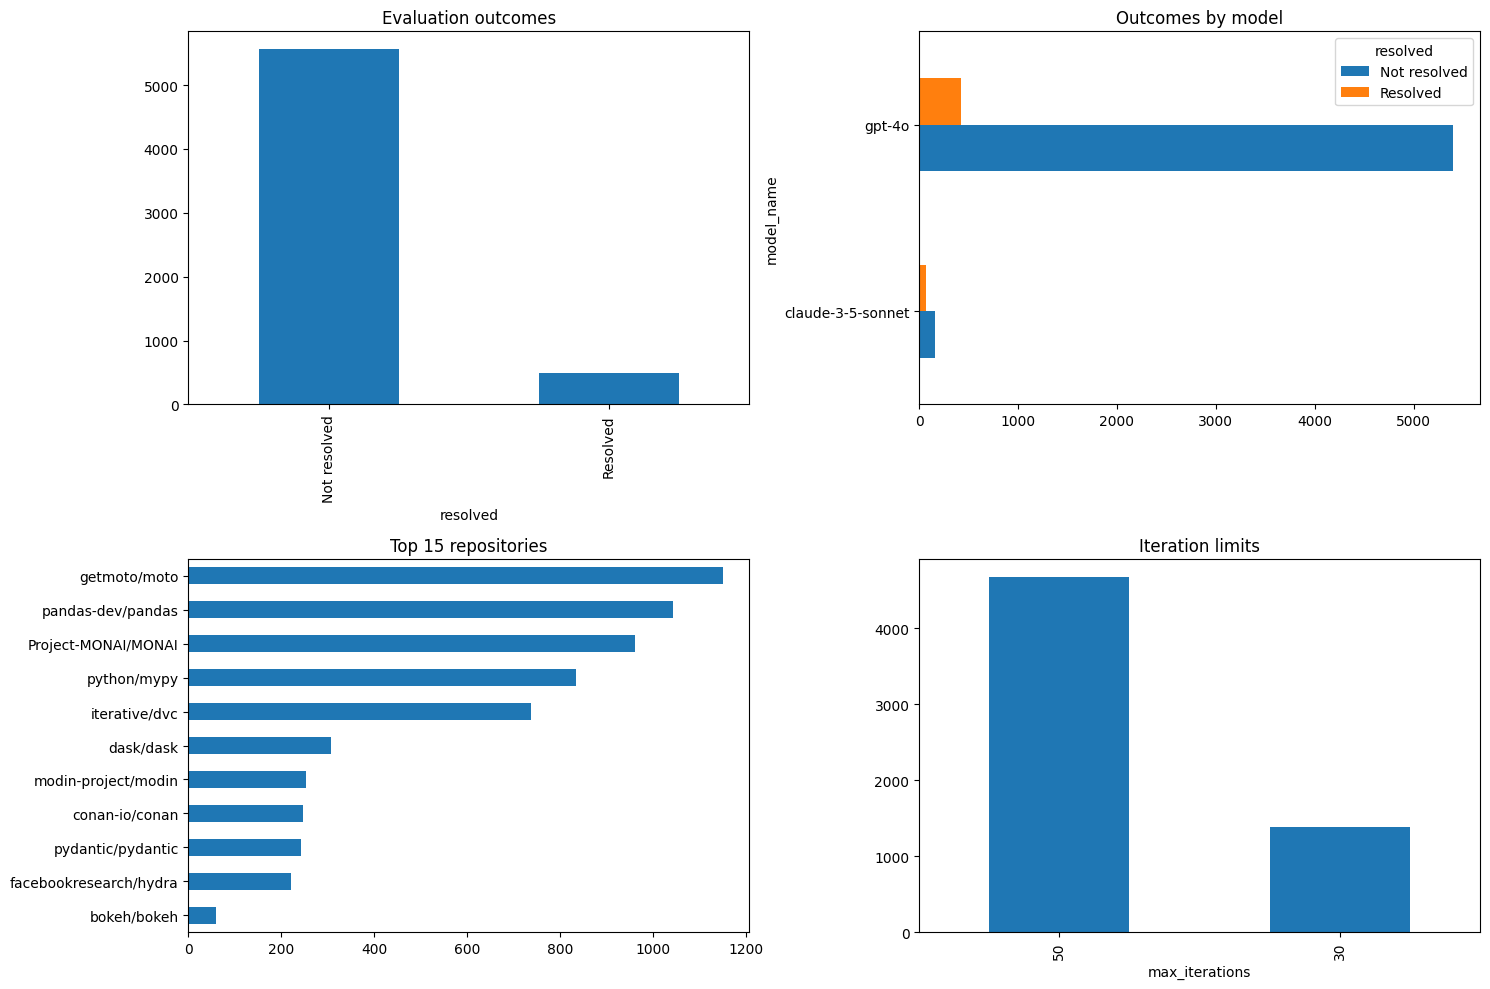

✓ Displayed distributions


In [26]:
import matplotlib.pyplot as plt

print(f"[STAGE] Plot distributions for {len(trace_df):,} attempts")
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
outcome = trace_df["resolved"].map({True: "Resolved", False: "Not resolved"}).fillna("Unknown")
outcome.value_counts().plot.bar(ax=axes[0, 0], title="Evaluation outcomes")
pd.crosstab(trace_df["model_name"].fillna("Unknown"), outcome).plot.barh(ax=axes[0, 1], title="Outcomes by model")
(trace_df["owner"].fillna("Unknown") + "/" + trace_df["repository"].fillna("Unknown")).value_counts().head(15).sort_values().plot.barh(ax=axes[1, 0], title="Top 15 repositories")
trace_df["max_iterations"].fillna("Unknown").value_counts().plot.bar(ax=axes[1, 1], title="Iteration limits")
fig.tight_layout()
plt.show()
print("✓ Displayed distributions")

### Trace length, message roles, and tool calls

Message counts include every recorded role. Tool counts show actual calls made by assistants, rather than the tools available in the definitions.

[STAGE] Summarize messages in 6,055 attempts


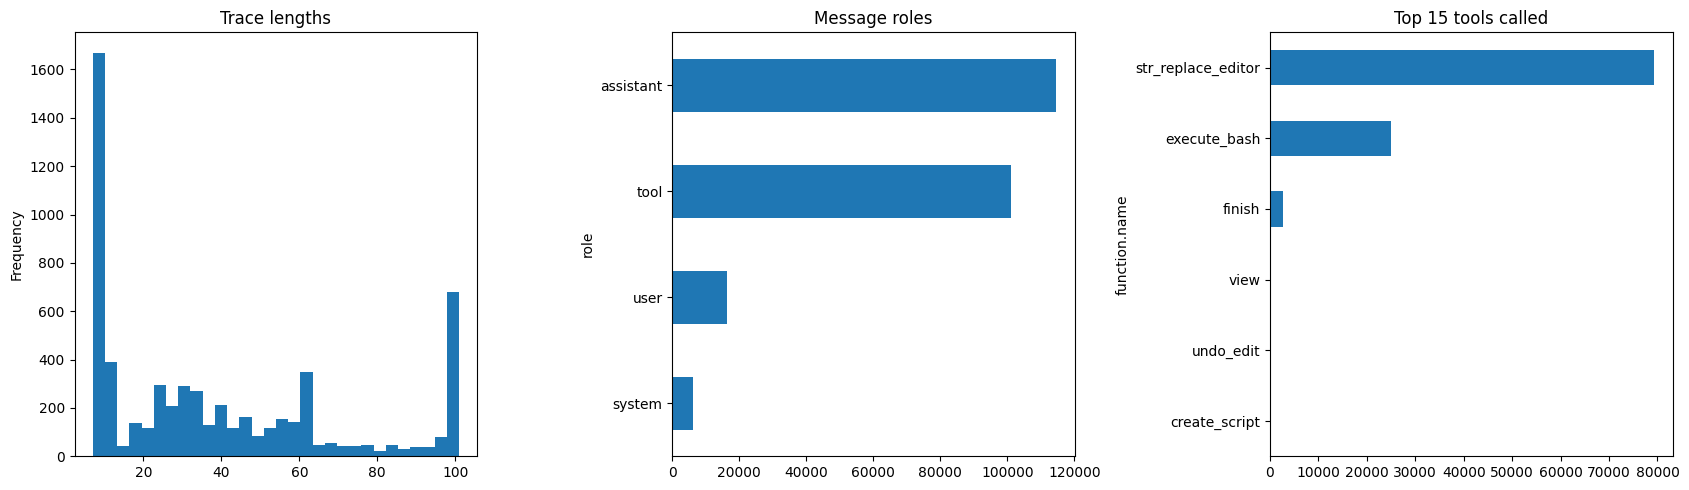

✓ Counted 237,851 messages and 106,882 tool calls


In [27]:
print(f"[STAGE] Summarize messages in {len(df):,} attempts")
message_counts = df["messages"].apply(lambda value: len(value) if value is not None else 0)
all_messages = pd.json_normalize(df["messages"].explode().dropna())
role_counts = all_messages.get("role", pd.Series(dtype="object")).fillna("Unknown").value_counts()
assistant_messages = all_messages[all_messages["role"] == "assistant"] if "role" in all_messages else all_messages
calls = assistant_messages.get("tool_calls", pd.Series(dtype="object")).explode().dropna()
tool_counts = pd.json_normalize(calls).get("function.name", pd.Series(dtype="object")).fillna("Unknown").value_counts()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
message_counts.plot.hist(bins=30, ax=axes[0], title="Trace lengths")
if not role_counts.empty:
    role_counts.sort_values().plot.barh(ax=axes[1], title="Message roles")
if not tool_counts.empty:
    tool_counts.head(15).sort_values().plot.barh(ax=axes[2], title="Top 15 tools called")
else:
    axes[2].set_title("No tool calls recorded")
fig.tight_layout()
plt.show()
print(f"✓ Counted {message_counts.sum():,} messages and {tool_counts.sum():,} tool calls")